# Generate source-level connectomes from the ProbConn atlas

---

## 🧪 - Experiment setup
- `src`: Source Space
- `tractogram`: Tractogram
- `ctx`: Cortical Mask
- `t12diff`: T1 subject space to Diffusion space transform
- `ras2tkras`: T1 subject space to FreeSurfer space transform

In [1]:
import mindmap as mm
import numpy as np
import pandas as pd

dm = mm.io.TutoManager("../../config.yml")
sub = "simf10"

src = dm.load(sub, "fwd", desc="sim")["src"]
parc = dm.load(sub, "dseg", space="fs", segmentation="multiconn2022", scale="4")
ras2tkras = dm.load(sub, "ras2tkras")
probcon = dm.load_ref("REF_CON")   # check this

## 🧬 - Data Processing

Preprocess atlas.

In [2]:
# convert atlas to binary adjacency matrix
consistency = probcon["matrices"]["consistency"][:,:]
length      = probcon["matrices"]["length"][:,:]
number      = probcon["matrices"]["numbStlines"][:,:]

consistency = np.nan_to_num(consistency)
length      = np.nan_to_num(length)
number      = np.nan_to_num(number)

regions = probcon["header"]["gmcoords"][:]

# Threshold atlas
atlas = np.bitwise_and(
    consistency > 65, 
    length > 0,
)
atlas = np.bitwise_and(
    atlas,
    number > 0,
)
atlas = length * atlas

Upscale connectome from atlas.

In [3]:
# connectivity of white matter tracts
# strength_matrix=consistency modulates sparsity per region pair by the atlas's own
# confidence signal instead of a single uniform value; sparsity_range is a starting
# point -- tune it against the validation metrics further down.
con_wm = mm.analysis.connectivity.connectome_from_atlas(
    src,
    parc,
    atlas,
    ras2tkras,
    strength_matrix = consistency,
    sparsity_range = (0.001, 0.05),
    deterministic = True,
)

# connectivity of gray matter tracts
con_gm = mm.analysis.connectivity.connectome_from_geometry(
    src,
    maximum_dist = 15,
    maximum_neigh = 3,
    weights = True,
)

# fuse connectomes
con = con_wm.copy()
gm_idx = np.argwhere(con_gm > 0)
con[gm_idx[:,0], gm_idx[:,1]] = con_gm[gm_idx[:,0], gm_idx[:,1]]

## 📊 - Visualization
Atlas structural connectome.

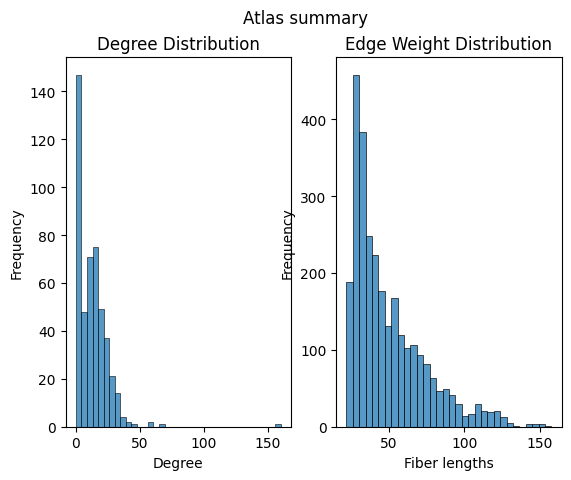

In [4]:
mm.viz.plot_con_summary(atlas, title = "Atlas summary", xlabel="Fiber lengths")

Atlas adjacency matrix.

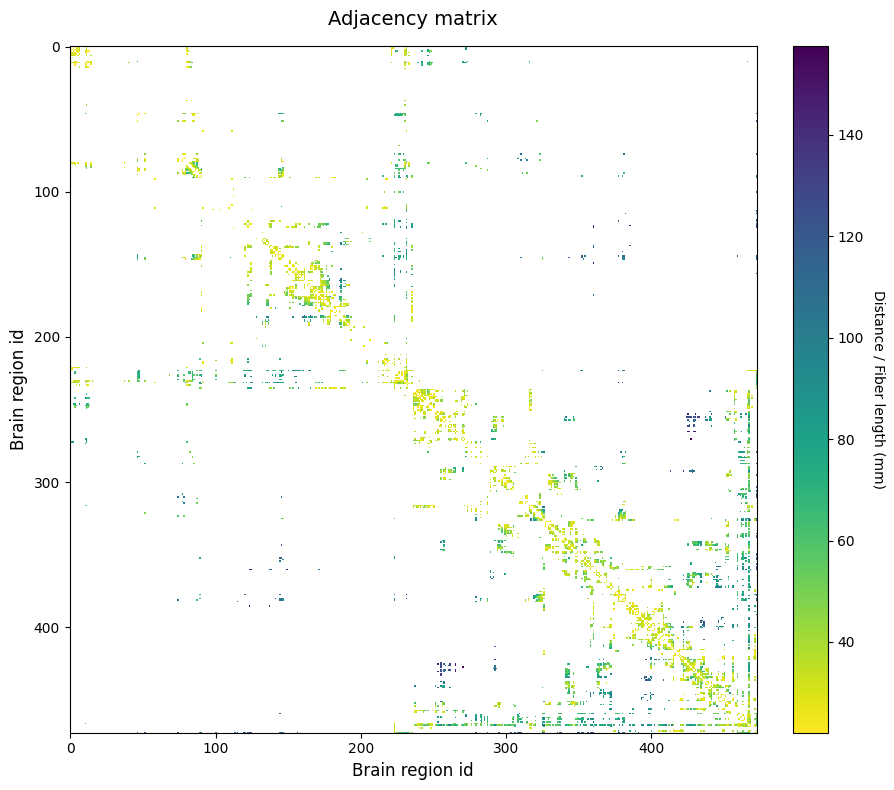

In [5]:
mm.viz.plot_adj_matrix(atlas, clabel="Distance / Fiber length (mm)", xylabel = "Brain region id")

Upscaled connectome summary.

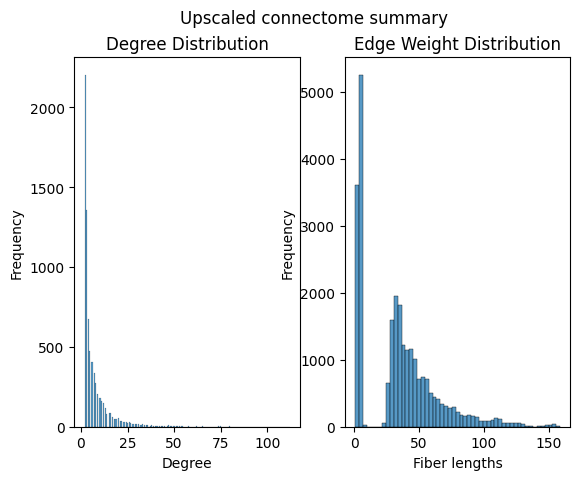

In [6]:
mm.viz.plot_con_summary(con, title = "Upscaled connectome summary", xlabel="Fiber lengths")

Upscaled connectome connectivity matrix.

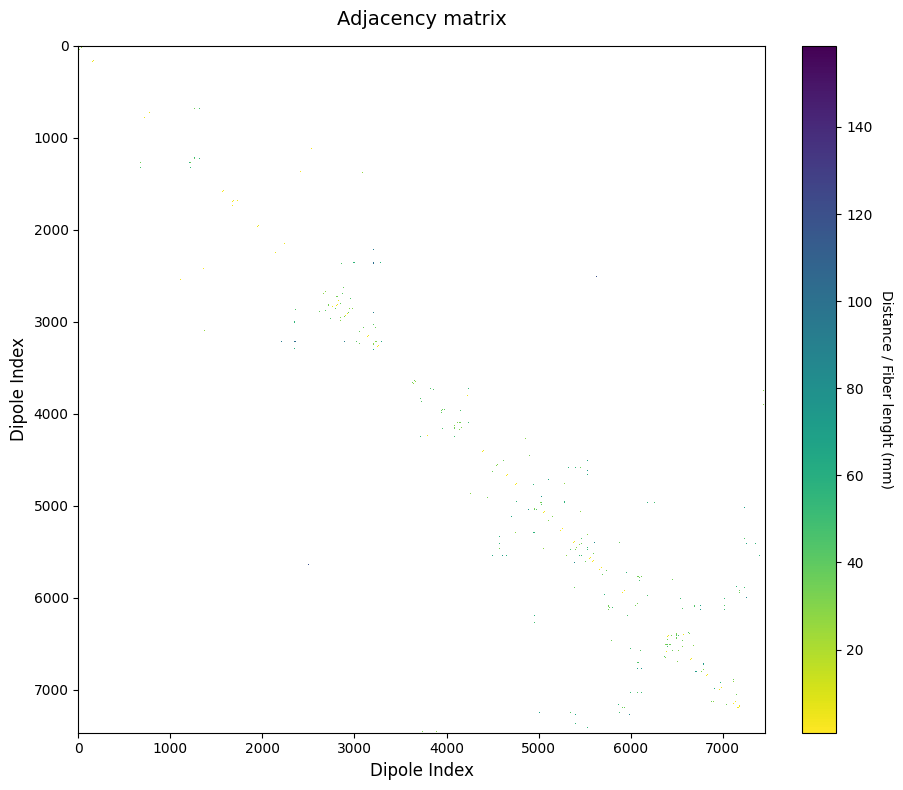

In [7]:
con_viz, _ = mm.analysis.connectivity.order_connectome_by_region(con, src, parc, ras2tkras)
mm.viz.plot_adj_matrix(con_viz, clabel="Distance / Fiber lenght (mm)")


Isolated nodes.

In [8]:
# Visualize isolated nodes
isolated_nodes = np.argwhere(np.sum(con>0, axis=1)==0).squeeze()
targets = np.zeros(mm.anatomy.source_space.get_ndipole(src))
targets[isolated_nodes] = 1

print(f"Number of isolated nodes: {int(targets.sum())}")
mm.viz.plot_brain(src, targets).show()

Number of isolated nodes: 0


Widget(value='<iframe src="http://localhost:42635/index.html?ui=P_0x7a6d2e829ed0_0&reconnect=auto" class="pyvi…

## ✅ - Validation metrics

Quantitative checks, complementing the plots above. Two different questions:
- **correctness**: did the upscaling preserve the atlas it was built from? (`block_conservation`, checked on `con_wm` since GM fusion isn't part of the atlas-upscaling step)
- **realism**: does the dipole-level connectome look like a real structural connectome? (`density`, `small_world_sigma`, `rich_club_curve`, `modularity`, `distance_decay_fit`, `hemispheric_symmetry`)

See `mindmap/analysis/connectivity/process.py`'s module docstring for the literature and target ranges behind each of these.

In [9]:
import matplotlib.pyplot as plt

from mindmap.analysis.connectivity import (
    density,
    small_world_sigma,
    rich_club_curve,
    modularity,
    distance_decay_fit_from_source_space,
    hemispheric_symmetry_from_source_space,
    block_conservation_from_atlas,
)

print("--- Atlas (region-level) ---")
print(f"density: {density(atlas):.3f}")

print("\n--- Correctness: block-averaging con_wm should recover `atlas` ---")
conservation = block_conservation_from_atlas(con_wm, src, parc, ras2tkras, atlas)
print(conservation)

print("\n--- Realism: upscaled connectome (dipole-level) ---")
print(f"density: {density(con):.4f}")
print("small-world:", small_world_sigma(con, n_null=10, seed=0))
print("modularity:", {k: v for k, v in modularity(con).items() if k != "community"})
print("hemispheric symmetry:", hemispheric_symmetry_from_source_space(con, src))

edr = distance_decay_fit_from_source_space(con, src, n_bins=30)
print(f"EDR fit: lambda={edr['lambda_']:.4f}, c={edr['c']:.3f}, r2={edr['r2']:.3f}")

rc = rich_club_curve(con, n_null=10, seed=0)
print("rich-club R_norm(k):", np.round(rc["R_norm"], 2))

--- Atlas (region-level) ---
density: 0.026

--- Correctness: block-averaging con_wm should recover `atlas` ---
{'r': np.float64(0.9991834528471748), 'mae': np.float64(1.5815913654269937), 'mean_bias': np.float64(0.03827874674667879), 'n_pairs': 2144}

--- Realism: upscaled connectome (dipole-level) ---
density: 0.0009
small-world: {'sigma': np.float64(9.806024311530088), 'C': np.float64(0.156272121030246), 'C_null': 0.005293689480844155, 'L': np.float64(12.499680936867408), 'L_null': 4.152109985936514}
modularity: {'q': np.float64(0.7979888737369506), 'n_communities': 32}
hemispheric symmetry: {'r': np.float64(0.11078505676617037), 'match_dist_mean': 2.8502772809029047, 'match_dist_max': 16.357343307166477}
EDR fit: lambda=0.1137, c=0.066, r2=0.146


/home/nino/miniconda3/envs/mindmap/lib/python3.11/site-packages/bct/algorithms/core.py:515: RuntimeWarning: invalid value encountered in scalar divide
  R[k] = Ek[k] / (Nk[k] * (Nk[k] - 1))


rich-club R_norm(k): [1.   1.04 1.13 1.17 1.2  1.23 1.26 1.28 1.3  1.33 1.35 1.38 1.4  1.41
 1.43 1.45 1.46 1.48 1.5  1.48 1.46 1.47 1.45 1.46 1.44 1.42 1.43 1.47
 1.44 1.45 1.49 1.51 1.52 1.53 1.53 1.51 1.52 1.49 1.5  1.52 1.56 1.52
 1.53 1.54 1.54 1.58 1.7  1.66 1.59 1.62 1.7  1.69 1.73 1.92 1.97 2.06
 2.   1.86 1.89 1.89 1.79 1.81 1.81 1.83 1.63 1.64 1.52 1.52 1.63 1.4
 1.4  1.12 1.04 1.25 1.22 0.86 1.11 1.11 1.11 2.5  2.5  0.   0.   0.
 0.   0.   0.   0.   0.   0.    nan  nan  nan  nan  nan  nan  nan  nan
  nan  nan  nan  nan  nan  nan  nan  nan  nan  nan  nan  nan  nan  nan]


/home/nino/Code/mindmap/mindmap/core/metric.py:890: RuntimeWarning: Mean of empty slice
  R_null_mean = np.nanmean(R_null, axis=0)


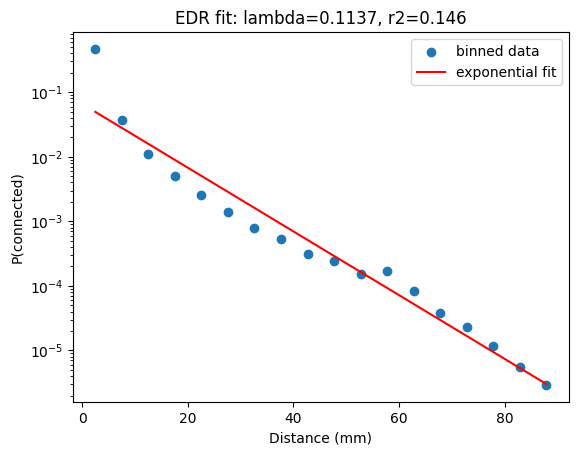

In [10]:
# visual check of the exponential-distance-rule (EDR) fit
fig, ax = plt.subplots()
valid = np.isfinite(edr["bin_prob"]) & (edr["bin_prob"] > 0)
ax.scatter(edr["bin_centers"][valid], edr["bin_prob"][valid], label="binned data")
fit_x = edr["bin_centers"][valid]
ax.plot(fit_x, edr["c"] * np.exp(-edr["lambda_"] * fit_x), color="red", label="exponential fit")
ax.set_yscale("log")
ax.set_xlabel("Distance (mm)")
ax.set_ylabel("P(connected)")
ax.set_title(f"EDR fit: lambda={edr['lambda_']:.4f}, r2={edr['r2']:.3f}")
ax.legend()
plt.show()